# NumPy
### CA0 @ EPS Course
#### Instructors: Dr. Tavassolipour, Dr. Vahabie

---

*Full Name:* MohammadMahdi Yari

*SID:* 810102532


---


# Setup Code
Before getting started we need to run some boilerplate code to set up our environment. You'll need to rerun this setup code each time you start the notebook.

First, run this cell to load the [autoreload](https://ipython.readthedocs.io/en/stable/config/extensions/autoreload.html?highlight=autoreload) extension. This allows us to edit `.py` source files, and re-import them into the notebook for a seamless editing and debugging experience.

In [2]:
%load_ext autoreload
%autoreload 2

### Google Colab Setup
Next we need to run a few commands to set up our environment on Google Colab. If you are running this notebook on a local machine you can skip this section.

Run the following cell to mount your Google Drive. Follow the link, sign in to your Google account (the same account you used to store this notebook!) and copy the authorization code into the text box that appears below.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google'

Now recall the path in your Google Drive where you've uploaded this notebook, fill it in below. If everything is working correctly then running the folowing cell should print the filenames from the assignment:

```
['numpy_basic.py', 'numpy_basic.ipynb']
```

In [4]:
import os

# TODO: Fill in the Google Drive path where you've uploaded the assignment
# Example: If you've  created a EPS folder and put all the files under CA0 folder, then 'EPS/CA0'
# GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = 'EPS/CA0'
GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = None 
GOOGLE_DRIVE_PATH = os.path.join('drive', 'My Drive', GOOGLE_DRIVE_PATH_AFTER_MYDRIVE)
print(os.listdir(GOOGLE_DRIVE_PATH))

TypeError: join() argument must be str, bytes, or os.PathLike object, not 'NoneType'

Once you have successfully mounted your Google Drive and located the path to this assignment, run the following cell to allow you to import from the `.py` files of this assignment. If it works correctly, it will print the following message as well as the last edit time for the  `numpy_basic.py` file:

```
Hello from numpy_basic.py!
```

In [5]:
import sys
sys.path.append(GOOGLE_DRIVE_PATH)

import time, os
os.environ["TZ"] = "'Asia/Tehran'"
time.tzset()

from numpy_basic import hello
hello()

numpy_path = os.path.join(GOOGLE_DRIVE_PATH, 'numpy_basic.py')
edit_time = time.ctime(os.path.getmtime(numpy_path))
print('numpy_basic.py last edited on %s' % edit_time)

NameError: name 'GOOGLE_DRIVE_PATH' is not defined

# Introduction

Python 3 and [NumPy](https://numpy.org/) will be used throughout the semseter, so it is important to be familiar with them. The materiald in this notebook are drawn from http://cs231n.github.io/python-numpy-tutorial/, https://github.com/kuleshov/cs228-material/blob/master/tutorials/python/cs228-python-tutorial.ipynb and DL course at SUT.

This notebook will walk you through many of the important features of Numpy that you will use throughout the semester. 

When completing the notebook, please adhere to the following rules:
- Do not write or modify any code outside of code blocks
- Do not add or delete any cells from the notebook. You may add new cells to perform scatch work, but delete them before submitting.
- Run all cells before submitting. You will only get credit for code that has been run.

This notebook contains many inline sanity checks for the code you write. However, **passing these sanity checks does not mean your code is correct!** In order to grade your work, we may run your code on additional inputs, and we check your code to make sure you've followed the specific guildelines for each implementation. You are encouraged to write additional test cases for the functions you are asked to write instead of solely relying on the sanity checks in the notebook.

# NumPy

[NumPy](https://numpy.org/) is a fundamental package for scientific computing with Python. At its core, NumPy provides a few key features:

- A multidimensional **Array** object.
- Comprehensive mathematical functions, random number generators, linear algebra routines.
- The core of NumPy is well-optimized C code.

This notebook will focus on the **Array API**, as it is the main part of NumPy that you will use for assignments.

You can find more information about NumPy by following one of the [oficial tutorials](https://numpy.org/learn/) or by [reading the documentation](https://numpy.org/doc/stable/).

To use NumPy, you first need to import the `numpy` package.

In [6]:
import numpy as np
print(np.__version__)

2.1.2


## Array Basics

### Creating and Accessing arrays

A `numpy` **array** is a multidimensional grid of values, all of the same type, and is indexed by a tuple of non-negative integers. The number of dimensions is the **rank** of the array; the **shape** of an array is a tuple of integers giving the size of the array along each dimension.

you can initialize `numpy` array from nested Python lists. you can access or mutate elements of a NumPy array using square brackets.

Accessing an element from a NumPy array returns a NumPy scalar; you can convert this to a Python scalar using the `.item()` method:

In [7]:
# Create a rank 1 array from a Python list
a = np.array([1, 2, 3])
print('Here is a:')
print(a)
print('type(a): ', type(a))
print('rank of a: ', np.linalg.matrix_rank(a))
print('a.shape: ', a.shape)

# Access elements using square brackets
print()
print('a[0]: ', a[0])
print('type(a[0]): ', type(a[0]))
print('type(a[0].item()): ', type(a[0].item()))

# Mutate elements using square brackets
a[1] = 10
print()
print('a after mutating:')
print(a)

Here is a:
[1 2 3]
type(a):  <class 'numpy.ndarray'>
rank of a:  1
a.shape:  (3,)

a[0]:  1
type(a[0]):  <class 'numpy.int64'>
type(a[0].item()):  <class 'int'>

a after mutating:
[ 1 10  3]


The example above shows a one-dimensional array; you can similarly create arrays with two or more dimensions:

In [8]:
# Create a two-dimensional array
b = np.array([[1, 2, 3], [4, 5, 5]])
print('Here is b:')
print(b)
print('rank of b:', np.linalg.matrix_rank(b))
print('b.shape: ', b.shape)

# Access elements from a multidimensional array
print()
print('b[0, 1]:', b[0, 1])
print('b[1, 2]:', b[1, 2])

# Mutate elements of a multidimensional array
b[1, 1] = 100
print()
print('b after mutating:')
print(b)

Here is b:
[[1 2 3]
 [4 5 5]]
rank of b: 2
b.shape:  (2, 3)

b[0, 1]: 2
b[1, 2]: 5

b after mutating:
[[  1   2   3]
 [  4 100   5]]


Now it's **your turn**. In the `numpy_basic.py` file, complete the implementation of the `create_sample_array`, `mutate_array`, and `count_array_elements` functions to practice constructing, mutating, and thinking about the shapes of arrays.

In [5]:
from numpy_basic import create_sample_array, mutate_array, count_array_elements

# Create a sample array
x = create_sample_array()
print('Here is the sample array:')
print(x)

# Mutate the array by setting a few elements
indices = [(0, 0), (1, 0), (1, 1)]
values = [4, 5, 6]
mutate_array(x, indices, values)
print('\nAfter mutating:')
print(x)
print('\nCorrect shape: ', x.shape == (3, 2))
print('x[0, 0] correct: ', x[0, 0].item() == 4)
print('x[1, 0] correct: ', x[1, 0].item() == 5)
print('x[1, 1] correct: ', x[1, 1].item() == 6)

# Check the number of elements in the sample array
num = count_array_elements(x)

print('\nNumber of elements in x: ', num)
print('Correctly counted: ', num == 6)

Here is the sample array:
[[  0  10]
 [100   0]
 [  0   0]]
[[ 4 10]
 [ 5  6]
 [ 0  0]]

After mutating:
[[ 4 10]
 [ 5  6]
 [ 0  0]]

Correct shape:  True
x[0, 0] correct:  True
x[1, 0] correct:  True
x[1, 1] correct:  True

Number of elements in x:  6
Correctly counted:  True


### Array constructors

NumPy provides many convenient methods for constructing arrays; this eliminates the need of using Python lists. For example:

- [`numpy.zeros`](https://numpy.org/doc/stable/reference/generated/numpy.zeros.html): Creates an array of all zeros
- [`numpy.ones`](https://numpy.org/doc/stable/reference/generated/numpy.ones.html): Creates an array of all ones
- [`numpy.random.rand`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.rand.html): Creates an array with uniform random numbers

You can find a full list of array creation operations [in the documentation](https://numpy.org/doc/stable/user/basics.creation.html).

In [9]:
# Create an array of all zeros
a = np.zeros((2, 3))
print('array of zeros:')
print(a)

# Create an array of all ones
b = np.ones((1, 2))
print('\narray of ones:')
print(b)

# Create a 3x3 identity matrix
c = np.eye(3)
print('\nidentity matrix:')
print(c)

# Array of random values
d = np.random.rand(4, 5)
print('\nrandom array:')
print(d)

array of zeros:
[[0. 0. 0.]
 [0. 0. 0.]]

array of ones:
[[1. 1.]]

identity matrix:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

random array:
[[0.66718867 0.67935267 0.55180567 0.78978125 0.50658987]
 [0.33718726 0.1633114  0.43668216 0.01170265 0.45413592]
 [0.66707457 0.12923371 0.40710652 0.42757452 0.76451656]
 [0.80896429 0.96162712 0.63719925 0.67223006 0.12402577]]


**Your turn**: In the `numpy_basic.py` file, complete the implementation of `create_array_of_pi` to practice using an array constructor.

Hint: [`numpy.full`](https://numpy.org/doc/stable/reference/generated/numpy.full.html)

In [6]:
from numpy_basic import create_array_of_pi

x = create_array_of_pi(4, 5)

print('x is an array:', type(x) == np.ndarray)
print('x has correct shape: ', x.shape == (4, 5))
print('x is filled with pi: ', (x == np.pi).all().item() == 1)

x is an array: True
x has correct shape:  True
x is filled with pi:  True


### Datatypes

In the examples above, you may have noticed that some of our arrays contain floating-point values, while others contain integer values.

NumPy provides a [large set of numeric datatypes](https://numpy.org/doc/stable/user/basics.types.html) that you can use to construct arrays. NumPy tries to guess the datatype when you create an array; but functions that construct arrays typically have a `dtype` argument that allows you to explicitly specify the datatype.

Each array has a `dtype` attribute that you can use to check its data type:

In [17]:
# Let numpy choose the datatype
x0 = np.array([1, 2])   # List of integers
x1 = np.array([1., 2.]) # List of floats
x2 = np.array([1., 2])  # Mixed list
print('dtype when numpy chooses for us:')
print('List of integers:', x0.dtype)
print('List of floats:', x1.dtype)
print('Mixed list:', x2.dtype)

# Force a particular datatype
y0 = np.array([1, 2], dtype=np.float32)  # 32-bit float
y1 = np.array([1, 2], dtype=np.int32)    # 32-bit (signed) integer
y2 = np.array([1, 2], dtype=np.int64)    # 64-bit (signed) integer
print('\ndtype when we force a datatype:')
print('32-bit float: ', y0.dtype)
print('32-bit integer: ', y1.dtype)
print('64-bit integer: ', y2.dtype)

# Other creation ops also take a dtype argument
z0 = np.ones((1, 2))  # Let numpy choose for us
z1 = np.ones((1, 2), dtype=np.int16) # 16-bit (signed) integer
z2 = np.ones((1, 2), dtype=np.uint8) # 8-bit (unsigned) integer
print('\nnumpy.ones with different dtypes')
print('default dtype:', z0.dtype)
print('16-bit integer:', z1.dtype)
print('8-bit unsigned integer:', z2.dtype)

dtype when numpy chooses for us:
List of integers: int64
List of floats: float64
Mixed list: float64

dtype when we force a datatype:
32-bit float:  float32
32-bit integer:  int32
64-bit integer:  int64

numpy.ones with different dtypes
default dtype: float64
16-bit integer: int16
8-bit unsigned integer: uint8


You can **cast** an array to another datatype using the [`.astype()`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.astype.html) and [`.view()`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.view.html) methods.


In [18]:
import numpy as np

x0 = np.eye(3, dtype=np.int64) # Create a 3x3 identity matrix with int64 data type
x1 = x0.astype(np.float32) # Cast to 32-bit float
x2 = x0.view(np.float64) # Cast to 64-bit float

print('x0:', x0.dtype)
print('x1:', x1.dtype)
print('x2:', x2.dtype)

x0: int64
x1: float32
x2: float64


NumPy provides several ways to create an array with the same datatype as another array:

- NumPy provides array constructors such as [`numpy.zeros_like()`](https://numpy.org/doc/stable/reference/generated/numpy.zeros_like.html) that create new arrays with the same shape and type as a given array.
- The array instance method [`.astype()`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.astype.html) can take an array `dtype` as an argument, in which case it casts to the argument.

In [21]:
x0 = np.eye(3, dtype=np.float64)        # Shape (3, 3), dtype numpy.float64
x1 = np.zeros_like(x0)                  # Shape (3, 3), dtype numpy.float64
x3 = np.ones((6, 7)).astype(x0.dtype)   # Shape (6, 7), dtype numpy.float64)
print('x0 shape is %r, dtype is %r' % (x0.shape, x0.dtype))
print('x1 shape is %r, dtype is %r' % (x1.shape, x1.dtype))
print('x3 shape is %r, dtype is %r' % (x3.shape, x3.dtype))

[[1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]]
x0 shape is (3, 3), dtype is dtype('float64')
x1 shape is (3, 3), dtype is dtype('float64')
x3 shape is (6, 7), dtype is dtype('float64')


**Your turn**: In the `numoy_basic.py` file, implement the `multiples_of_ten` function which should create and return an array of dtype `numpy.float64` containing all the multiples of ten in a given range.

Hint: [`numpy.arange`](https://numpy.org/doc/stable/reference/generated/numpy.arange.html#numpy-arange)

In [7]:
from numpy_basic import multiples_of_ten

start = 5
stop = 25
x = multiples_of_ten(start, stop)
print('Correct dtype: ', x.dtype == np.float64)
print('Correct shape: ', x.shape == (2,))
print('Correct values: ', x.tolist() == [10, 20])

# If there are no multiples of ten in the given range you should return an empty array
start = 5
stop = 7
x = multiples_of_ten(start, stop)
print('\nCorrect dtype: ', x.dtype == np.float64)
print('Correct shape: ', x.shape == (0,))

Correct dtype:  True
Correct shape:  True
Correct values:  True

Correct dtype:  True
Correct shape:  True


Even though NumPy provides a large number of numeric datatypes, the most commonly used datatypes are:

- `numpy.float32`: Standard floating-point type; Nearly all arithmetic is done using this type.
- `numpy.int64`: Typically used to store indices
- `numpy.bool`: Stores boolean values: 0 is false and 1 is true

## Array indexing

You have already seen how to get and set individual elements of NumPy arrays. NumPy also provides many other ways of indexing into arrays. Getting comfortable with these different options makes it easy to modify different parts of arrays with ease.

### Slice indexing

Similar to Python lists, NumPy arrays can be **sliced** using the syntax `start:stop` or `start:stop:step`. The `stop` index is always exclusive, meaning it is the first element not included in the slice.

Start and stop indices can be negative, in which case they count backward from the end of the array.

In [25]:
a = np.array([0, 11, 22, 33, 44, 55, 66])
print(0, a)        # (0) Original array
print(1, a[2:5])   # (1) Elements between index 2 and 5
print(2, a[2:])    # (2) Elements after index 2
print(3, a[:5])    # (3) Elements before index 5
print(4, a[:])     # (4) All elements
print(5, a[1:5:2]) # (5) Every second element between indices 1 and 5
print(6, a[:-1])   # (6) All but the last element
print(7, a[-4::2]) # (7) Every second element, starting from the fourth-last

0 [ 0 11 22 33 44 55 66]
1 [22 33 44]
2 [22 33 44 55 66]
3 [ 0 11 22 33 44]
4 [ 0 11 22 33 44 55 66]
5 [11 33]
6 [ 0 11 22 33 44 55]
7 [33 55]


For multidimensional arrays, you can provide a slice or integer for each dimension of the array in order to extract different types of subarrays:

In [27]:
# Create the following rank 2 array with shape (3, 4)
# [[ 1  2  3  4]
#  [ 5  6  7  8]
#  [ 9 10 11 12]]
a = np.array([[1,2,3,4], [5,6,7,8], [9,10,11,12]])
print('Original array:')
print(a)
print('shape: ', a.shape)

# Get row 1, and all columns. 
print('\nSingle row:')
print(a[1, :])
print(a[1])  # Gives the same result; we can omit : for trailing dimensions
print('shape: ', a[1].shape)

print('\nSingle column:')
print(a[:, 1])
print('shape: ', a[:, 1].shape)

# Get the first two rows and the last three columns
print('\nFirst two rows, last two columns:')
print(a[:2, -3:])
print('shape: ', a[:2, -3:].shape)

# Get every other row, and columns at index 1 and 2
print('\nEvery other row, middle columns:')
print(a[::2, 1:3])
print('shape: ', a[::2, 1:3].shape)

Original array:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
shape:  (3, 4)

Single row:
[5 6 7 8]
[5 6 7 8]
shape:  (4,)

Single column:
[ 2  6 10]
shape:  (3,)

First two rows, last two columns:
[[2 3 4]
 [6 7 8]]
shape:  (2, 3)

Every other row, middle columns:
[[ 2  3]
 [10 11]]
shape:  (2, 2)


There are two common ways to access a single row or column of an array: using an integer that reduces the dimensionality by one, and using a length-one slice that preserves the original dimensionality. Note that this behavior is different from MATLAB.

In [28]:
# Create the following rank 2 array with shape (3, 4)
a = np.array([[1,2,3,4], [5,6,7,8], [9,10,11,12]])
print('Original array')
print(a)

row_r1 = a[1, :]    # Rank 1 view of the second row of a  
row_r2 = a[1:2, :]  # Rank 2 view of the second row of a
print('\nTwo ways of accessing a single row:')
print(row_r1, row_r1.shape)
print(row_r2, row_r2.shape)

# We can make the same distinction when accessing columns::
col_r1 = a[:, 1]
col_r2 = a[:, 1:2]
print('\nTwo ways of accessing a single column:')
print(col_r1, col_r1.shape)
print(col_r2, col_r2.shape)

Original array
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

Two ways of accessing a single row:
[5 6 7 8] (4,)
[[5 6 7 8]] (1, 4)

Two ways of accessing a single column:
[ 2  6 10] (3,)
[[ 2]
 [ 6]
 [10]] (3, 1)


Slicing an array returns a **view** of the same data, so modifying it will also modify the original array. To avoid this, you can use the `copy()` method to create a copy of the array.

In [29]:
# Create an array, a slice, and a copy of a slice
a = np.array([[1, 2, 3, 4], [5, 6, 7, 8]])
b = a[0, 1:]
c = a[0, 1:].copy()
print('Before mutating:')
print(a)
print(b)
print(c)

a[0, 1] = 20  # a[0, 1] and b[0] point to the same element
b[1] = 30     # b[1] and a[0, 2] point to the same element
c[2] = 40     # c is a copy, so it has its own data
print('\nAfter mutating:')
print(a)
print(b)
print(c)

print('Are data pointers of a and b the same?', np.shares_memory(a, b))
print('Are data pointers of a and c the same?', np.shares_memory(a, c))

Before mutating:
[[1 2 3 4]
 [5 6 7 8]]
[2 3 4]
[2 3 4]

After mutating:
[[ 1 20 30  4]
 [ 5  6  7  8]]
[20 30  4]
[ 2  3 40]
Are data pointers of a and b the same? True
Are data pointers of a and c the same? False


**Your turn**: In the `numpy_basic.py` file, implement the `slice_indexing_practice` function to practice slicing arrays with different types of slices.

In [8]:
# We will use this helper function to check your results
def check(orig, actual, expected):
    if not type(actual) == np.ndarray:
        return False
    expected = np.array(expected)
    same_elements = (actual == expected).all().item()
    same_storage = np.shares_memory(orig, actual)
    return same_elements and same_storage

In [10]:
from numpy_basic import slice_indexing_practice

# Create the following rank 2 array of shape (3, 5)
# [[ 1  2  3  4  5]
#  [ 6  7  8  9 10]
#  [11 12 13 14 15]]
x = np.array([[1, 2, 3, 4, 5], [6, 7, 8, 8, 10], [11, 12, 13, 14, 15]])
out = slice_indexing_practice(x)

last_row = out[0]
print('last_row:')
print(last_row)
correct = check(x, last_row, [11, 12, 13, 14, 15])
print('Correct: %r\n' % correct)

third_col = out[1]
print('third_col:')
print(third_col)
correct = check(x, third_col, [[3], [8], [13]])
print('Correct: %r\n' % correct)

first_two_rows_three_cols = out[2]
print('first_two_rows_three_cols:')
print(first_two_rows_three_cols)
correct = check(x, first_two_rows_three_cols, [[1, 2, 3], [6, 7, 8]])
print('Correct: %r\n' % correct)

even_rows_odd_cols = out[3]
print('even_rows_odd_cols:')
print(even_rows_odd_cols)
correct = check(x, even_rows_odd_cols, [[2, 4], [12, 14]])
print('Correct: %r\n' % correct)

last_row:
[11 12 13 14 15]
Correct: True

third_col:
[[ 3]
 [ 8]
 [13]]
Correct: True

first_two_rows_three_cols:
[[1 2 3]
 [6 7 8]]
Correct: True

even_rows_odd_cols:
[[ 2  4]
 [12 14]]
Correct: True



So far you have used slicing to **access** subarrays; we can also use slicing to **modify** subarrays by writing assignment expressions where the left-hand side is a slice expression, and the right-hand side is a constant or an array of the correct shape:

In [11]:
a = np.zeros((2, 4), dtype=np.int64)
a[:, :2] = 1
a[:, 2:] = np.array([[2, 3], [4, 5]])
print(a)

[[1 1 2 3]
 [1 1 4 5]]


**Your turn**: In the `numpy_basic.py` file, implement the `slice_assignment_practice` function to practice modifying arrays using slicing assignment statements.

This function should use slicing assignment operations to modify the first four rows and first six columns of the input array so they are equal to

This function should use slicing assignment operations to modify the first four rows and first six columns of the input array so that they are equal to

$$
\begin{bmatrix}
0 & 1 & 2 & 2 & 2 & 2 \\
0 & 1 & 2 & 2 & 2 & 2 \\
3 & 4 & 3 & 4 & 5 & 5 \\
3 & 4 & 3 & 4 & 5 & 5 \\
\end{bmatrix}
$$

Your implementation must follow the following guidelines:
- You should mutate the array x in-place and return it.
- You should only modify the first 4 rows and first 6 columns; all other
elements should remain unchanged.
- You may only mutate the array using slice assignment operations, where you
assign an integer to a slice of the array.
- You must use at most 6 slicing operations to achieve the desired result.

In [41]:
from numpy_basic import slice_assignment_practice

x = np.zeros((5, 7), dtype=np.int64)
print('Here is x before calling slice_assignment_practice:')
print(x)
slice_assignment_practice(x)
print('Here is x after calling slice assignment practice:')
print(x)

expected = [
    [0, 1, 2, 2, 2, 2, 0],
    [0, 1, 2, 2, 2, 2, 0],
    [3, 4, 3, 4, 5, 5, 0],
    [3, 4, 3, 4, 5, 5, 0],
    [0, 0, 0, 0, 0, 0, 0],
]
print('Correct: ', x.tolist() == expected)

Here is x before calling slice_assignment_practice:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]
Here is x after calling slice assignment practice:
[[0 1 2 2 2 2 0]
 [0 1 2 2 2 2 0]
 [3 4 3 4 5 5 0]
 [3 4 3 4 5 5 0]
 [0 0 0 0 0 0 0]]
Correct:  True


### Integer array indexing

When you index a NumPy array using slicing, the resulting array view will always be a subarray of the original array. While this is powerful, it can also be restrictive.

Alternatively, we can use **index arrays** to index arrays, which offers much greater flexibility than slicing.

For example, index arrays can be used to reorder the rows or columns of an array:

In [42]:
# Create the following rank 2 array with shape (3, 4)
# [[ 1  2  3  4]
#  [ 5  6  7  8]
#  [ 9 10 11 12]]
a = np.array([[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12]])
print('Original array:')
print(a)

# Create a new array of shape (5, 4) by reordering rows from a:
# - First two rows same as the first row of a
# - Third row is the same as the last row of a
# - Fourth and fifth rows are the same as the second row from a
idx = [0, 0, 2, 1, 1]  # index arrays can be Python lists of integers
print('\nReordered rows:')
print(a[idx])

# Create a new array of shape (3, 4) by reversing the columns from a
idx = np.array([3, 2, 1, 0])  # Index arrays can be int64 numpy arrays
print('\nReordered columns:')
print(a[:, idx])

Original array:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

Reordered rows:
[[ 1  2  3  4]
 [ 1  2  3  4]
 [ 9 10 11 12]
 [ 5  6  7  8]
 [ 5  6  7  8]]

Reordered columns:
[[ 4  3  2  1]
 [ 8  7  6  5]
 [12 11 10  9]]


More generally, given index arrays `idx0` and `idx1` with `N` elements each, `a[idx0, idx1]` is equivalent to:

```
numpy.array([
  a[idx0[0], idx1[0]],
  a[idx0[1], idx1[1]],
  ...,
  a[idx0[N - 1], idx1[N - 1]]
])
```

(A similar pattern extends to arrays with more than two dimensions)
For example, you can use this to get or set the diagonal of an array:

In [43]:
a = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
print('Original array:')
print(a)

idx = [0, 1, 2]
print('\nGet the diagonal:')
print(a[idx, idx])

# Modify the diagonal
a[idx, idx] = np.array([11, 22, 33])
print('\nAfter setting the diagonal:')
print(a)

Original array:
[[1 2 3]
 [4 5 6]
 [7 8 9]]

Get the diagonal:
[1 5 9]

After setting the diagonal:
[[11  2  3]
 [ 4 22  6]
 [ 7  8 33]]


One useful trick with integer array indexing is selecting or mutating one element from each row or column of a matrix:

In [44]:
# Create a new array from which we will select elements
a = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12]])
print('Original array:')
print(a)

# Take on element from each row of a:
# from row 0, take element 1;
# from row 1, take element 2;
# from row 2, take element 1;
# from row 3, take element 0
idx0 = np.arange(a.shape[0])  # Quick way to build [0, 1, 2, 3]
idx1 = np.array([1, 2, 1, 0])
print('\nSelect one element from each row:')
print(a[idx0, idx1])

# Now set each of those elements to zero
a[idx0, idx1] = 0
print('\nAfter modifying one element from each row:')
print(a)

Original array:
[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]

Select one element from each row:
[ 2  6  8 10]

After modifying one element from each row:
[[ 1  0  3]
 [ 4  5  0]
 [ 7  0  9]
 [ 0 11 12]]


**Your turn**: in the `numpy_basic.py` file, implement the `shuffle_cols`, `reverse_rows`, and `take_one_elem_per_col` functions to practice using integer indexing to manipulate arrays. In each of these functions, your implementation should construct the output array **using a single indexing operation on the input**.

In [12]:
from numpy_basic import shuffle_cols, reverse_rows, take_one_elem_per_col

# Build an array of shape (4, 3):
# [[ 1,  2,  3],
#  [ 4,  5,  6],
#  [ 7,  8,  9],
#  [10, 11, 12]]
x = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12]])
print('Here is x:')
print(x)

y1 = shuffle_cols(x)
print('\nHere is shuffle_cols(x):')
print(y1)
expected = [[1, 1, 3, 2], [4, 4, 6, 5], [7, 7, 9, 8], [10, 10, 12, 11]]
y1_correct = type(y1) == np.ndarray and y1.tolist() == expected
print('Correct: %r\n' % y1_correct)

y2 = reverse_rows(x)
print('Here is reverse_rows(x):')
print(y2)
expected = [[10, 11, 12], [7, 8, 9], [4, 5, 6], [1, 2, 3]]
y2_correct = type(y2) == np.ndarray and y2.tolist() == expected
print('Correct: %r\n' % y2_correct)

y3 = take_one_elem_per_col(x)
print('Here is take_one_elem_per_col(x):')
print(y3)
expected = [4, 2, 12]
y3_correct = type(y3) == np.ndarray and y3.tolist() == expected
print('Correct: %r' % y3_correct)

Here is x:
[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]

Here is shuffle_cols(x):
[[ 1  1  3  2]
 [ 4  4  6  5]
 [ 7  7  9  8]
 [10 10 12 11]]
Correct: True

Here is reverse_rows(x):
[[10 11 12]
 [ 7  8  9]
 [ 4  5  6]
 [ 1  2  3]]
Correct: True

Here is take_one_elem_per_col(x):
[ 4  2 12]
Correct: True


### Boolean array indexing

Boolean array indexing allows you to select or modify elements of an array based on a boolean mask. This type of indexing is commonly used to choose or change elements that satisfy a specific condition.

In NumPy, arrays of dtype `numpy.bool` are used to hold boolean masks.

In [49]:
a = np.array([[1,2], [3, 4], [5, 6]])
print('Original array:')
print(a)

# Find the elements of a that are bigger than 3. The mask has the same shape as
# a, where each element of mask tells whether the corresponding element of a
# is greater than three.
mask = (a > 3)
print('\nMask array:')
print(mask)

# We can use the mask to construct a rank-1 array containing the elements of a
# that are selected by the mask
print('\nSelecting elements with the mask:')
print(a[mask])

# We can also use boolean masks to modify arrays; for example this sets all
# elements <= 3 to zero:
a[a <= 3] = 0
print('\nAfter modifying with a mask:')
print(a)

Original array:
[[1 2]
 [3 4]
 [5 6]]

Mask array:
[[False False]
 [False  True]
 [ True  True]]

Selecting elements with the mask:
[4 5 6]

After modifying with a mask:
[[0 0]
 [0 4]
 [5 6]]


**Your turn**: In the `numpy_basic.py` file, implement the `count_negative_entries` function which counts the number of negative entries in a numpy array. You can easily accomplish this using boolean array indexing. Your implementation should perform only a single indexing operation on the input array.

In [13]:
from numpy_basic import count_negative_entries

# Make a few test cases
np.random.seed(0)
x0 = np.array([[-1, -1, 0], [0, 1, 2], [3, 4, 5]])
x1 = np.array([0, 1, 2, 3])
x2 = np.random.randn(100, 100)
print('Correct for x0: ', count_negative_entries(x0) == 2)
print('Correct for x1: ', count_negative_entries(x1) == 0)
print('Correct for x2: ', count_negative_entries(x2) == 5107)

Correct for x0:  True
Correct for x1:  True
Correct for x2:  True


Now implement the `make_one_hot` function that creates a matrix of **one-hot vectors** from a list of Python integers.

A one-hot vector for an integer $n$ is a vector that has a 1 in its $n$th slot, and zeros in all other slots. One-hot vectors are commonly used to represent categorical variables in machine learning models.

For example, given a list `[1, 4, 3, 2]` of integers, your function should produce the array:

```
[[0 1 0 0 0],
 [0 0 0 0 1],
 [0 0 0 1 0],
 [0 0 1 0 0]]
```

Here the first row corresponds to the first element of the list: it has a one at index 1, and zeros at all other indices. The second row corresponds to the second element of the list: it has a one at index 4, and zeros at all other indices. The other rows follow the same pattern. The output has just enough columns so that none of the rows go out-of-bounds: the largest index in the input is 4, so the output matrix has 5 columns.

In [14]:
from numpy_basic import make_one_hot

def check_one_hot(x, y):
    C = y.shape[1]
    for i, n in enumerate(x):
        if n >= C: return False
        for j in range(C):
            expected = 1.0 if j == n else 0.0
            if y[i, j].item() != expected: return False
        return True
      
x0 = [1, 4, 3, 2]
y0 = make_one_hot(x0)
print('Here is y0:')
print(y0)
print('y0 correct: ', check_one_hot(x0, y0))

x1 = [1, 3, 5, 7, 6, 2]
y1 = make_one_hot(x1)
print('\nHere is y1:')
print(y1)
print('y1 correct: ', check_one_hot(x1, y1))

Here is y0:
[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0.]]
y0 correct:  True

Here is y1:
[[0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0.]]
y1 correct:  True


## Reshaping operations

### Reshape

NumPy provides many ways to manipulate the shape of arrays. The simplest example is [`.reshape()`](https://numpy.org/doc/stable/reference/generated/numpy.reshape.html#numpy-reshape): This returns a new array with the same number of elements as its input, but with a different shape.

We can use `.reshape()` to flatten matrices into vectors, and to convert rank-1 vectors into rank-2 row or column matrices:

In [15]:

x0 = np.array([[1, 2, 3, 4], [5, 6, 7, 8]])
print('Original array:')
print(x0)
print('shape:', x0.shape)

# Flatten x0 into a rank 1 vector of shape (8,)
x1 = x0.reshape(8)
print('\nFlattened array:')
print(x1)
print('shape:', x1.shape)

# Convert x1 to a rank 2 "row vector" of shape (1, 8)
x2 = x1.reshape(1, 8)
print('\nRow vector:')
print(x2)
print('shape:', x2.shape)

# Convert x1 to a rank 2 "column vector" of shape (8, 1)
x3 = x1.reshape(8, 1)
print('\nColumn vector:')
print(x3)
print('shape:', x3.shape)

# Convert x1 to a rank 3 array of shape (2, 2, 2):
x4 = x1.reshape(2, 2, 2)
print('\nRank 3 array:')
print(x4)
print('shape:', x4.shape)

Original array:
[[1 2 3 4]
 [5 6 7 8]]
shape: (2, 4)

Flattened array:
[1 2 3 4 5 6 7 8]
shape: (8,)

Row vector:
[[1 2 3 4 5 6 7 8]]
shape: (1, 8)

Column vector:
[[1]
 [2]
 [3]
 [4]
 [5]
 [6]
 [7]
 [8]]
shape: (8, 1)

Rank 3 array:
[[[1 2]
  [3 4]]

 [[5 6]
  [7 8]]]
shape: (2, 2, 2)


As a convenience, calls to `.reshape()` may include a single -1 argument; this puts enough elements on that dimension so that the output has the same shape as the input. This makes it easy to write some reshape operations in a way that is agnostic to the shape of the array:

In [16]:
# We can reuse these functions for arrays of different shapes
def flatten(x):
    return x.reshape(-1)

def make_row_vec(x):
    return x.reshape(1, -1)

x0 = np.array([[1, 2, 3], [4, 5, 6]])
x0_flat = flatten(x0)
x0_row = make_row_vec(x0)
print('x0:')
print(x0)
print('x0_flat:')
print(x0_flat)
print('x0_row:')
print(x0_row)

x1 = np.array([[1, 2], [3, 4]])
x1_flat = flatten(x1)
x1_row = make_row_vec(x1)
print('\nx1:')
print(x1)
print('x1_flat:')
print(x1_flat)
print('x1_row:')
print(x1_row)

x0:
[[1 2 3]
 [4 5 6]]
x0_flat:
[1 2 3 4 5 6]
x0_row:
[[1 2 3 4 5 6]]

x1:
[[1 2]
 [3 4]]
x1_flat:
[1 2 3 4]
x1_row:
[[1 2 3 4]]


As its name implies, an array returned by `.reshape()` shares the same data as the input, so changes to one will affect the other and vice-versa:

In [56]:
x = np.array([[1, 2, 3], [4, 5, 6]])
x_flat = x.reshape(-1)
print('x before modifying:')
print(x)
print('x_flat before modifying:')
print(x_flat)

x[0, 0] = 10   # x[0, 0] and x_flat[0] point to the same data
x_flat[1] = 20 # x_flat[1] and x[0, 1] point to the same data

print('\nx after modifying:')
print(x)
print('x_flat after modifying:')
print(x_flat)

x before modifying:
[[1 2 3]
 [4 5 6]]
x_flat before modifying:
[1 2 3 4 5 6]

x after modifying:
[[10 20  3]
 [ 4  5  6]]
x_flat after modifying:
[10 20  3  4  5  6]


### Swapping axes

Another common reshape operation you might want to perform is transposing a matrix. You might be surprised if you try to transpose a matrix with `.reshape()`: The `reshape()` function takes elements in row-major order, so **you cannot transpose matrices with `.reshape()`**.

In general, you should only use `.reshape()` to add new dimensions to an array, or to collapse adjacent dimensions of an array.

For other types of reshape operations, you usually need to use a function that can swap axes of an array. The simplest such function is `.transpose()`, specificially for transposing matrices. It is available both as a [function in the `numpy` module](https://numpy.org/doc/stable/reference/generated/numpy.transpose.html), and as an [array instance method](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.transpose.html).
Also you can use the array instance attribute [`.T`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.T.html):

In [57]:
x = np.array([[1, 2, 3], [4, 5, 6]])
print('Original matrix:')
print(x)
print('\nTransposing with view DOES NOT WORK!')
print(x.reshape(3, 2))
print('\nTransposed matrix:')
print(np.transpose(x))
print(x.transpose())
print(x.T)

Original matrix:
[[1 2 3]
 [4 5 6]]

Transposing with view DOES NOT WORK!
[[1 2]
 [3 4]
 [5 6]]

Transposed matrix:
[[1 4]
 [2 5]
 [3 6]]
[[1 4]
 [2 5]
 [3 6]]
[[1 4]
 [2 5]
 [3 6]]


For arrays with more than two dimensions, you can use the  [`numpy.transpose`](https://numpy.org/doc/stable/reference/generated/numpy.transpose.html#numpy-transpose) function to swap arbitrary dimensions.

In [58]:
# Create an array of shape (2, 3, 4)
x0 = np.array([
     [[1,  2,  3,  4],
      [5,  6,  7,  8],
      [9, 10, 11, 12]],
     [[13, 14, 15, 16],
      [17, 18, 19, 20],
      [21, 22, 23, 24]]])
print('Original array:')
print(x0)
print('shape:', x0.shape)

# Swap axes 1 and 2; shape is (2, 4, 3)
x1 = x0.transpose((0, 2, 1))
print('\nSwap axes 1 and 2:')
print(x1)
print(x1.shape)

# Permute axes; the argument (0, 2, 1) means:
# - Make the old dimension 0 appear at dimension 0;
# - Make the old dimension 2 appear at dimension 1;
# - Make the old dimension 1 appear at dimension 2
# This results in an array of shape (2, 4, 3)

Original array:
[[[ 1  2  3  4]
  [ 5  6  7  8]
  [ 9 10 11 12]]

 [[13 14 15 16]
  [17 18 19 20]
  [21 22 23 24]]]
shape: (2, 3, 4)

Swap axes 1 and 2:
[[[ 1  5  9]
  [ 2  6 10]
  [ 3  7 11]
  [ 4  8 12]]

 [[13 17 21]
  [14 18 22]
  [15 19 23]
  [16 20 24]]]
(2, 4, 3)


### **Your turn**

In the `numpy_basic.py` file, implement the `reshape_practice` function to practice using reshape operations on arrays. Given the 1-dimensional input array `x` containing the integer numbers from 0 to 23 in order, it should return the following output array `y` of shape `(3, 8)` by using reshape operations on x:


```
y = array([[ 0,  1,  2,  3, 12, 13, 14, 15],
            [ 4,  5,  6,  7, 16, 17, 18, 19],
            [ 8,  9, 10, 11, 20, 21, 22, 23]])
```

Hint: You will need to create an intermediate array of rank 3

In [17]:
from numpy_basic import reshape_practice

x = np.arange(24)
print('Here is x:')
print(x)
y = reshape_practice(x)
print('Here is y:')
print(y)

expected = [
    [0, 1,  2,  3, 12, 13, 14, 15],
    [4, 5,  6,  7, 16, 17, 18, 19],
    [8, 9, 10, 11, 20, 21, 22, 23]]
print('Correct:', y.tolist() == expected)

Here is x:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]
Here is y:
[[ 0  1  2  3 12 13 14 15]
 [ 4  5  6  7 16 17 18 19]
 [ 8  9 10 11 20 21 22 23]]
Correct: True


## Array operations
So far you have seen how to construct, access, and reshape arrays. But one of the most important reasons to use arrays is performing computation! NumPy provides many different operations to perform computations on arrays.

### Elementwise operations

Basic mathematical functions operate elementwise on arrays, and are available as operator overloads, and as functions in the `numpy` module; They both produce the same results:

In [63]:
x = np.array([[1, 2, 3, 4]], dtype=np.float32)
y = np.array([[5, 6, 7, 8]], dtype=np.float32)

# Elementwise sum; all give the same result
print('Elementwise sum:')
print(x + y)
print(np.add(x, y))

# Elementwise difference
print('\nElementwise difference:')
print(x - y)
print(np.subtract(x, y))

# Elementwise product
print('\nElementwise product:')
print(x * y)
print(np.multiply(x, y))

# Elementwise division
print('\nElementwise division')
print(x / y)
print(np.divide(x, y))

# Elementwise power
print('\nElementwise power')
print(x ** y)
print(np.power(x, y))

Elementwise sum:
[[ 6.  8. 10. 12.]]
[[ 6.  8. 10. 12.]]

Elementwise difference:
[[-4. -4. -4. -4.]]
[[-4. -4. -4. -4.]]

Elementwise product:
[[ 5. 12. 21. 32.]]
[[ 5. 12. 21. 32.]]

Elementwise division
[[0.2        0.33333334 0.42857143 0.5       ]]
[[0.2        0.33333334 0.42857143 0.5       ]]

Elementwise power
[[1.0000e+00 6.4000e+01 2.1870e+03 6.5536e+04]]
[[1.0000e+00 6.4000e+01 2.1870e+03 6.5536e+04]]


NumPy also provides many standard mathematical functions; these are available as functions in the `numpy` module.
You can find a full list of all available mathematical functions [in the documentation](https://numpy.org/doc/stable/reference/routines.math.html).

In [64]:
x = np.array([[1, 2, 3, 4]], dtype=np.float32)

print('Square root:')
print(np.sqrt(x))

print('\nTrig functions:')
print(np.sin(x))
print(np.cos(x))

Square root:
[[1.        1.4142135 1.7320508 2.       ]]

Trig functions:
[[ 0.841471   0.9092974  0.14112   -0.7568025]]
[[ 0.5403023 -0.4161468 -0.9899925 -0.6536436]]


### Reduction operations

So far you've seen basic arithmetic operations on arrays that operate elementwise. You may sometimes want to perform operations that aggregate over a part or all of an array, such as a summation; these are called **reduction** operations.

Most reduction operations are available both as functions in the `numpy` module and as instance methods on `array` objects.

The simplest reduction operation is summation. You can use the [`.sum()`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.sum.html) function (or eqivalently [`numpy.sum`](https://numpy.org/doc/stable/reference/generated/numpy.sum.html)) to reduce either an entire array, or to reduce along only one dimension of the array using the `axis` argument:

In [65]:
x = np.array([[1, 2, 3], 
                  [4, 5, 6]], dtype=np.float32)
print('Original array:')
print(x)

print('\nSum over entire array:')
print(np.sum(x))
print(x.sum())

# We can sum over each row:
print('\nSum of each row:')
print(np.sum(x, axis=0))
print(x.sum(axis=0))

# Sum over each column:
print('\nSum of each column:')
print(np.sum(x, axis=1))
print(x.sum(axis=1))

Original array:
[[1. 2. 3.]
 [4. 5. 6.]]

Sum over entire array:
21.0
21.0

Sum of each row:
[5. 7. 9.]
[5. 7. 9.]

Sum of each column:
[ 6. 15.]
[ 6. 15.]


Other useful reduction operations include [`mean`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html), [`min`](https://numpy.org/doc/stable/reference/generated/numpy.min.html), and [`max`](https://numpy.org/doc/stable/reference/generated/numpy.max.html).

In [66]:
x = np.array([[2, 4, 3, 5], [3, 3, 5, 2]], dtype=np.float32)
print('Original array:')
print(x, x.shape)

# Finding the overall minimum only returns a single value
print('\nOverall minimum: ', x.min())

# Compute the minimum along each column;
# The minimum of the first column is 2, and it appears at index 0;
# the minimum of the second column is 3 and it appears at index 1; etc
print('\nMinimum along each column:', x.min(axis=0))

# Compute the minimum along each row;
print('\nMinimum along each row:', x.min(axis=1))

Original array:
[[2. 4. 3. 5.]
 [3. 3. 5. 2.]] (2, 4)

Overall minimum:  2.0

Minimum along each column: [2. 3. 3. 2.]

Minimum along each row: [2. 2.]


Reduction operations *reduce* the rank of arrays: the dimension over which you perform the reduction will be removed from the shape of the output. If you pass `keepdims=True` to a reduction operation, the specified dimension will not be removed; the output array will instead have a shape of 1 in that dimension.

When you are working with multidimensional arrays, thinking about rows and columns can become confusing; instead it's more useful to think about the shape that will result from each operation. For example:

In [67]:
# Create an array of shape (128, 10, 3, 64, 64)
x = np.random.randn(128, 10, 3, 64, 64)
print(x.shape)

# Take the mean over axisension 1; shape is now (128, 3, 64, 64)
x = x.mean(axis=1)
print(x.shape)

# Take the sum over axisension 2; shape is now (128, 3, 64)
x = x.sum(axis=2)
print(x.shape)

# Take the mean over axisension 1, but keep the axisension from being eliminated
# by passing keepaxis=True; shape is now (128, 1, 64)
x = x.mean(axis=1, keepdims=True)
print(x.shape)

(128, 10, 3, 64, 64)
(128, 3, 64, 64)
(128, 3, 64)
(128, 1, 64)


**Your turn**: In the `numpy_basic.py` file, implement the `zero_row_min` function which sets the minimum value along each row of an array to zero. You should use reduction and indexing operations, and you should not use any explicit loops.

Hint: [`clone`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.copy.html), [`argmin`](https://numpy.org/doc/stable/reference/generated/numpy.argmin.html)

In [18]:
from numpy_basic import zero_row_min

x0 = np.array([[10, 20, 30], [2, 5, 1]])
print('Here is x0:')
print(x0)
y0 = zero_row_min(x0)
print('Here is y0:')
print(y0)
expected = [[0, 20, 30], [2, 5, 0]]
y0_correct = np.ndarray == type(y0) and y0.tolist() == expected
print('y0 correct: ', y0_correct)

x1 = np.array([[2, 5, 10, -1], [1, 3, 2, 4], [5, 6, 2, 10]])
print('\nHere is x1:')
print(x1)
y1 = zero_row_min(x1)
print('Here is y1:')
print(y1)
expected = [[2, 5, 10, 0], [0, 3, 2, 4], [5, 6, 0, 10]]
y1_correct = np.ndarray == type(y1) and y1.tolist() == expected
print('y1 correct: ', y1_correct)

Here is x0:
[[10 20 30]
 [ 2  5  1]]
Here is y0:
[[ 0 20 30]
 [ 2  5  0]]
y0 correct:  True

Here is x1:
[[ 2  5 10 -1]
 [ 1  3  2  4]
 [ 5  6  2 10]]
Here is y1:
[[ 2  5 10  0]
 [ 0  3  2  4]
 [ 5  6  0 10]]
y1 correct:  True


### Matrix operations

Note that unlike MATLAB, * is elementwise multiplication, not matrix multiplication. NumPy provides a number of linear algebra functions that compute different types of vector and matrix products. The most commonly used are:

- [`numpy.dot`](https://numpy.org/doc/stable/reference/generated/numpy.dot.html): Computes inner product of vectors
- [`numpy.matmul`](https://numpy.org/doc/stable/reference/generated/numpy.matmul.html): Computes matrix-matrix products


Here is an example of using `numpy.dot` to compute inner products. Like the other mathematical operators you've seen, most linear algebra operators are available both as functions in the `numpy` module and as instance methods of arrays:

In [19]:
v = np.array([9,10], dtype=np.float32)
w = np.array([11, 12], dtype=np.float32)

# Inner product of vectors
print('Dot products:')
print(np.dot(v, w))
print(v.dot(w))

# dot only works for vectors -- it will give an error for arrays of rank > 1
x = np.array([[1,2],[3,4]], dtype=np.float32)
y = np.array([[5,6],[7,8]], dtype=np.float32)
try:
  print(x.dot(y))
except RuntimeError as e:
  print(e)
  

Dot products:
219.0
219.0
[[19. 22.]
 [43. 50.]]


**Your turn**: In the `numpy_basic.py` file, implement the `batched_matrix_multiply` function. You should implement two pathways within this function: one uses an explicit loop over the batch dimension, and the other performs the batched matrix multiply using a single NumPy operation and no explicit loop.

Hint: [`numpy.stack`](https://numpy.org/doc/stable/reference/generated/numpy.stack.html).



In [20]:
from numpy_basic import batched_matrix_multiply

B, N, M, P = 2, 3, 5, 4
x = np.random.randn(B, N, M)
y = np.random.randn(B, M, P)
z_expected = np.stack([x[0] @ y[0], x[1] @ y[1]])

# The two may not return exactly the same result; different linear algebra
# routines often return slightly different results due to the fact that
# floating-point math is non-exact and non-associative.
z1 = batched_matrix_multiply(x, y, use_loop=True)
z1_diff = np.abs(z1 - z_expected).max().item()
print('z1 difference: ', z1_diff)
print('z1 difference within tolerance: ', z1_diff < 1e-6)

z2 = batched_matrix_multiply(x, y, use_loop=False)
z2_diff = np.abs(z2 - z_expected).max().item()
print('\nz2 difference: ', z2_diff)
print('z2 difference within tolerance: ', z2_diff < 1e-6)

z1 difference:  0.0
z1 difference within tolerance:  True

z2 difference:  0.0
z2 difference within tolerance:  True


### Vectorization
In many cases, using NumPy operators to handle looping internally instead of explicit Python loops in your code will make your code faster. This coding style, called **vectorization**, avoids the Python interpreter overhead, and can also parallelize the computation better(e.g. across CPU cores, or on GPUs). Whenever possible you should strive to write vectorized code.

Run the following to compare the speed of the `batched_matrix_multiply` with `use_loop=True` and `use_loop=False`.

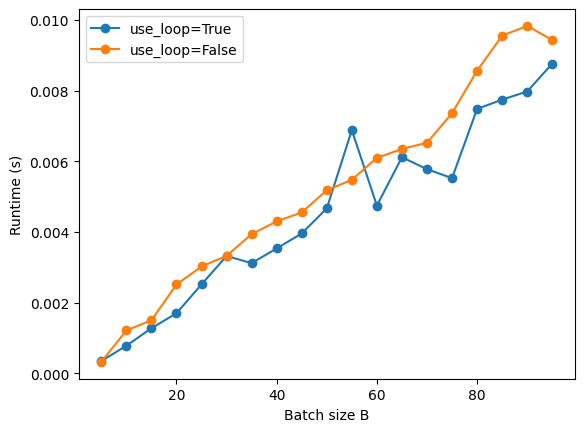

In [21]:
import time
import matplotlib.pyplot as plt
from numpy_basic import batched_matrix_multiply

N, M, P = 100, 100, 100
loop_times = []
no_loop_times = []
Bs = list(range(5, 100, 5))
num_trials = 20
for B in Bs:
    loop_trials = []
    no_loop_trials = []
    for trial in range(num_trials):
        x = np.random.randn(B, N, M)
        y = np.random.randn(B, M, P)
        t0 = time.time()
        z1 = batched_matrix_multiply(x, y, use_loop=True)
        t1 = time.time()
        z2 = batched_matrix_multiply(x, y, use_loop=False)
        t2 = time.time()
        loop_trials.append(t1 - t0)
        no_loop_trials.append(t2 - t1)
    loop_mean = np.array(loop_trials).mean().item()
    no_loop_mean = np.array(no_loop_trials).mean().item()
    loop_times.append(loop_mean)
    no_loop_times.append(no_loop_mean)
    
plt.plot(Bs, loop_times, 'o-', label='use_loop=True')
plt.plot(Bs, no_loop_times, 'o-', label='use_loop=False')
plt.xlabel('Batch size B')
plt.ylabel('Runtime (s)')
plt.legend()
plt.show()

## Broadcasting

Broadcasting is a powerful mechanism that allows NumPy to work with arrays of different shapes when performing arithmetic operations. Frequently you have a small array and a large array, and you want to use the small array multiple times to perform some operation on the large array.

For example, suppose that you want to add a constant vector to each row of an array. You can do it like this:


In [77]:
# We will add the vector v to each row of the matrix x,
# storing the result in the matrix y
x = np.array([[1,2,3], [4,5,6], [7,8,9], [10, 11, 12]])
v = np.array([1, 0, 1])
y = np.zeros_like(x)   # Create an empty matrix with the same shape as x

# Add the vector v to each row of the matrix x with an explicit loop
for i in range(4):
    y[i, :] = x[i, :] + v

print(y)

[[ 2  2  4]
 [ 5  5  7]
 [ 8  8 10]
 [11 11 13]]


This works; however, when the array x is very large, computing an explicit loop in Python could be slow. Note that adding the vector v to each row of the array x is equivalent to forming an array vv by stacking multiple copies of v vertically, then performing elementwise summation of x and vv. You could implement this approach like this:


In [78]:
vv = v[np.newaxis, :].repeat(4, 0)  # Stack 4 copies of v on top of each other
print(vv)                           # Prints "[[1 0 1]
                                    #          [1 0 1]
                                    #          [1 0 1]
                                    #          [1 0 1]]"

[[1 0 1]
 [1 0 1]
 [1 0 1]
 [1 0 1]]


In [79]:
y = x + vv  # Add x and vv elementwise
print(y)

[[ 2  2  4]
 [ 5  5  7]
 [ 8  8 10]
 [11 11 13]]


NumPy broadcasting allows you to perform this computation without actually creating multiple copies of v. Consider this version, using broadcasting:

In [80]:
# We will add the vector v to each row of the matrix x,
# storing the result in the matrix y
x = np.array([[1,2,3], [4,5,6], [7,8,9], [10, 11, 12]])
v = np.array([1, 0, 1])
y = x + v  # Add v to each row of x using broadcasting
print(y)

[[ 2  2  4]
 [ 5  5  7]
 [ 8  8 10]
 [11 11 13]]


The line y = x + v works even though x has shape (4, 3) and v has shape (3,) due to broadcasting; this line works as if v actually had shape (4, 3), where each row was a copy of v, and the sum was performed elementwise.

Broadcasting two arrays together follows these rules:

1.   If the arrays do not have the same rank, prepend the shape of the lower rank array with 1s until both shapes have the same length.
2.   The two arrays are said to be *compatible* in a dimension if they have the same size in that dimension, or if one of the arrays has size 1 in that dimension.
3.   The arrays can be broadcasted together if they are compatible in all dimensions.
4.   After broadcasting, each array behaves as if it had shape equal to the elementwise maximum of shapes of the two input arrays.
5.   In any dimension where one array has size 1 and the other array has size greater than 1, the first array behaves as if it is copied along that dimension

If this explanation does not make sense, try reading the explanation from the [documentation](https://numpy.org/doc/stable/user/basics.broadcasting.html).

Broadcasting usually happens implicitly inside many NumPy operators. However you can also broadcast explicitly using the [`numpy.broadcast`](https://numpy.org/doc/stable/reference/generated/numpy.broadcast.html#numpy.broadcast) function:

In [81]:
x = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12]])
v = np.array([1, 0, 1])
print('Here is x (before broadcasting):')
print(x)
print('x.shape: ', x.shape)
print('\nHere is v (before broadcasting):')
print(v)
print('v.shape: ', v.shape)

xx, vv = np.broadcast_arrays(x, v)
print('Here is xx (after) broadcasting):')
print(xx)
print('xx.shape: ', x.shape)
print('\nHere is vv (after broadcasting):')
print(vv)
print('vv.shape: ', vv.shape)

Here is x (before broadcasting):
[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]
x.shape:  (4, 3)

Here is v (before broadcasting):
[1 0 1]
v.shape:  (3,)
Here is xx (after) broadcasting):
[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]
xx.shape:  (4, 3)

Here is vv (after broadcasting):
[[1 0 1]
 [1 0 1]
 [1 0 1]
 [1 0 1]]
vv.shape:  (4, 3)


Notice that after broadcasting, `x` remains the same but `v` has an extra dimension prepended to its shape, and it is duplicated to have the same shape as `x`; since they have the same shape after broadcasting they can be added elementwise.

Broadcasting lets you implement many different operations easily. For example you can compute an outer product of vectors:

In [82]:
# Compute outer product of vectors
v = np.array([1, 2, 3])  # v has shape (3,)
w = np.array([4, 5])     # w has shape (2,)
# To compute an outer product, we first reshape v to be a column
# vector of shape (3, 1); we can then broadcast it against w to yield
# an output of shape (3, 2), which is the outer product of v and w:
print(v.reshape((3, 1)) * w)

[[ 4  5]
 [ 8 10]
 [12 15]]


You can add a vector to each row of a matrix:

In [83]:
x = np.array([[1, 2, 3], [4, 5, 6]])  # x has shape (2, 3)
v = np.array([1, 2, 3])               # v has shape (3,)
print('Here is the matrix:')
print(x)
print('\nHere is the vector:')
print(v)

# x has shape (2, 3) and v has shape (3,) so they broadcast to (2, 3),
# giving the following matrix:
print('\nAdd the vector to each row of the matrix:')
print(x + v)

Here is the matrix:
[[1 2 3]
 [4 5 6]]

Here is the vector:
[1 2 3]

Add the vector to each row of the matrix:
[[2 4 6]
 [5 7 9]]


You can add a vector to each column of a matrix:

In [84]:
x = np.array([[1, 2, 3], [4, 5, 6]])  # x has shape (2, 3)
w = np.array([4, 5])                  # w has shape (2,)
print('Here is the matrix:')
print(x)
print('\nHere is the vector:')
print(w)

# x has shape (2, 3) and w has shape (2,). We reshape w to (2, 1);
# then when we add the two the result broadcasts to (2, 3):
print('\nAdd the vector to each column of the matrix:')
print(x + w.reshape((-1, 1)))

# Another solution is the following:
# 1. Transpose x so it has shape (3, 2)
# 2. Since w has shape (2,), adding will broadcast to (3, 2)
# 3. Transpose the result, resulting in a shape (2, 3)
print((x.T + w).T)

Here is the matrix:
[[1 2 3]
 [4 5 6]]

Here is the vector:
[4 5]

Add the vector to each column of the matrix:
[[ 5  6  7]
 [ 9 10 11]]
[[ 5  6  7]
 [ 9 10 11]]


Multiply an array by a set of constants:

In [85]:
x = np.array([[1, 2, 3], [4, 5, 6]])  # x has shape (2, 3)
c = np.array([1, 10, 11, 100])        # c has shape (4)
print('Here is the matrix:')
print(x)
print('\nHere is the vector:')
print(c)

# We do the following:
# 1. Reshape c from (4,) to (4, 1, 1)
# 2. x has shape (2, 3). Since they have different ranks, when we multiply the
#    two, x behaves as if its shape were (1, 2, 3)
# 3. The result of the broadcast multiplication between array of shape
#    (4, 1, 1) and (1, 2, 3) has shape (4, 2, 3)
# 4. The result y has shape (4, 2, 3), and y[i] (shape (2, 3)) is equal to
#    c[i] * x
y = c.reshape((-1, 1, 1)) * x
print('\nMultiply x by a set of constants:')
print(y)

Here is the matrix:
[[1 2 3]
 [4 5 6]]

Here is the vector:
[  1  10  11 100]

Multiply x by a set of constants:
[[[  1   2   3]
  [  4   5   6]]

 [[ 10  20  30]
  [ 40  50  60]]

 [[ 11  22  33]
  [ 44  55  66]]

 [[100 200 300]
  [400 500 600]]]


**Your turn**: In the `numpy_basic.py` file, implement the `normalize_columns` function that normalizes the columns of a matrix. It should compute the mean and standard deviation of each column, then subtract the mean and divide it by the standard deviation for each element in the column.

Example:
```
x = [[ 0,  30,  600],
     [ 1,  10,  200],
     [-1,  20,  400]]
```
- The first column has mean 0 and std 1
- The second column has mean 20 and std 10
- The third column has mean 400 and std 200

After normalizing the columns, the result should be:
```
y = [[ 0,  1,  1],
     [ 1, -1, -1],
     [-1,  0,  0]]
```

Recall that given scalars $x_1,\ldots,x_M$ the mean $\mu$ and standard deviation $\sigma$ are given by

$$\mu=\frac{1}{M}\sum_{i=1}^M x_i \hspace{4pc} \sigma = \sqrt{\frac{1}{M-1}\sum_{i=1}^M(x_i-\mu)^2}$$

In [22]:
from numpy_basic import normalize_columns

x = np.array([[0., 30., 600.], [1., 10., 200.], [-1., 20., 400.]])
y = normalize_columns(x)
print('Here is x:')
print(x)
print('Here is y:')
print(y)

x_expected = [[0., 30., 600.], [1., 10., 200.], [-1., 20., 400.]]
y_expected = [[0., 1., 1.], [1., -1., -1.], [-1., 0., 0.]]
y_correct = y.tolist() == y_expected
x_correct = x.tolist() == x_expected
print('y correct: ', y_correct)
print('x unchanged: ', x_correct)

Here is x:
[[  0.  30. 600.]
 [  1.  10. 200.]
 [ -1.  20. 400.]]
Here is y:
[[ 0  1  1]
 [ 1 -1 -1]
 [-1  0  0]]
y correct:  True
x unchanged:  True


### Out-of-place vs in-place operators
Most NumPy operators are classified into one of the two categories:
- **Out-of-place operators:** returns a new array. Most NumPy operators behave in this way.
- **In-place operators:** modifies and returns the input array. Operators in the `numpy` namespace can be made in-place using the `out=` keyword argument.

For example:

In [23]:
# Out-of-place addition creates and returns a new array without modifying the inputs:
x = np.array([1, 2, 3])
y = np.array([3, 4, 5])
print('Out-of-place addition:')
print('Before addition:')
print('x: ', x)
print('y: ', y)
z = np.add(x, y)  # Same as z = x + y
print('\nAfter addition (x and y unchanged):')
print('x: ', x)
print('y: ', y)
print('z: ', z)
print('z is x: ', z is x)
print('z is y: ', z is y)

# In-place addition modifies the input array:
print('\n\nIn-place Addition:')
print('Before addition:')
print('x: ', x)
print('y: ', y)
x += y  # Same np.add(x, y, out=x)
print('\nAfter addition (x is modified):')
print('x: ', x)
print('y: ', y)
print('z: ', z)
print('z is x: ', z is x)
print('z is y: ', z is y)

Out-of-place addition:
Before addition:
x:  [1 2 3]
y:  [3 4 5]

After addition (x and y unchanged):
x:  [1 2 3]
y:  [3 4 5]
z:  [4 6 8]
z is x:  False
z is y:  False


In-place Addition:
Before addition:
x:  [1 2 3]
y:  [3 4 5]

After addition (x is modified):
x:  [4 6 8]
y:  [3 4 5]
z:  [4 6 8]
z is x:  False
z is y:  False


In general, **you should avoid in-place operations** since they can cause problems.

Done!